# 1.0 · Exploración inicial de los datos crudos

**Objetivo:** entender los CSV de MiBici antes de limpiarlos y justificar cada regla de
limpieza de `TripCleaner` (`mibici_demand/dataset.py`) con evidencia de los datos.

**Requisito:** haber descargado los datos con `make download`
(o `python -m mibici_demand.download`).

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from mibici_demand.config import CLEANING_PARAMS, INVALID_ID_VALUES, RAW_TRIPS_DIR
from mibici_demand.dataset import buscar_nulos, estandarizar_datos, leer_datos, load_stations

2026-10-25 03:13:56.532 | INFO     | mibici_demand.config:<module>:16 - PROJ_ROOT path is: C:\Users\Sam\Downloads\mibici-demand-main\mibici-demand-main


## 1. Archivos disponibles

In [2]:
archivos = sorted(RAW_TRIPS_DIR.glob("datos_abiertos_*.csv"))
print(f"{len(archivos)} archivos mensuales: {archivos[0].name} ... {archivos[-1].name}")

142 archivos mensuales: datos_abiertos_2014_12.csv ... datos_abiertos_2026_09.csv


## 2. ¿Los encabezados son iguales en todos los meses?
Se lee solo la primera línea de cada archivo. Si aparece más de una combinación de
columnas, `estandarizar_datos` es la que las unifica (por ejemplo, la columna
`Año_de_nacimiento` con la codificación rota).

In [3]:
import csv

def encabezado(archivo):
    primera = archivo.open("rb").readline()
    try:
        texto, codificacion = primera.decode("utf-8-sig"), "utf-8"
    except UnicodeDecodeError:
        texto, codificacion = primera.decode("cp1252"), "cp1252"
    # csv.reader quita las comillas: "Viaje_Id" y Viaje_Id cuentan como el mismo nombre
    return tuple(next(csv.reader([texto]))), codificacion

resumen = pd.DataFrame(
    [(a.name, *encabezado(a)) for a in archivos], columns=["archivo", "columnas", "codificacion"]
)
print(resumen["codificacion"].value_counts(), "\n")
resumen["columnas"].value_counts()

codificacion
utf-8     99
cp1252    43
Name: count, dtype: int64 



columnas
(Viaje_Id, Usuario_Id, Genero, Año_de_nacimiento, Inicio_del_viaje, Fin_del_viaje, Origen_Id, Destino_Id)    140
(Viaje_Id, Usuario_Id, Genero, A}äe_nacimiento, Inicio_del_viaje, Fin_del_viaje, Origen_Id, Destino_Id)        2
Name: count, dtype: int64

## 3. Nulos e IDs inválidos en todo el periodo
`buscar_nulos` recorre todos los meses. La segunda tabla suma los IDs inválidos
definidos en `INVALID_ID_VALUES` (el ID 0), porque en la práctica también son datos faltantes.

In [4]:
INVALID_ID_VALUES

{'Origen_Id': [0], 'Destino_Id': [0], 'Viaje_Id': [0]}

In [5]:
nulos_originales, nulos_con_invalidos = buscar_nulos()
nulos_con_invalidos.round(3)

Nulos por mes:   1%|▏         | 2/142 [00:00<00:11, 12.59it/s]

2026-10-25 03:13:57.031 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo datos_abiertos_2014_12.csv
2026-10-25 03:13:57.101 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo datos_abiertos_2015_01.csv
2026-10-25 03:13:57.191 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo datos_abiertos_2015_02.csv


Nulos por mes:   3%|▎         | 4/142 [00:00<00:12, 11.20it/s]

2026-10-25 03:13:57.285 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo datos_abiertos_2015_03.csv
2026-10-25 03:13:57.382 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo datos_abiertos_2015_04.csv


Nulos por mes:   4%|▍         | 6/142 [00:00<00:12, 10.54it/s]

...

2026-10-25 03:15:37.523 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo datos_abiertos_2026_08.csv


Nulos por mes:  99%|█████████▉| 141/142 [01:41<00:00,  1.03it/s]

2026-10-25 03:15:38.552 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo datos_abiertos_2026_09.csv


Nulos por mes: 100%|██████████| 142/142 [01:42<00:00,  1.38it/s]


,nulos_originales,ids_invalidos,nulos,filas,nulos_pct
columna,,,,,
Genero,144508,0,144508,39078984,0.370
Año_de_nacimiento,81064,0,81064,38284446,0.212
A}äe_nacimiento,587,0,587,794538,0.074
Destino_Id,0,0,0,39078984,0.000
Fin_del_viaje,0,0,0,39078984,0.000
Inicio_del_viaje,0,0,0,39078984,0.000
Origen_Id,0,0,0,39078984,0.000
Usuario_Id,0,0,0,39078984,0.000
Viaje_Id,0,0,0,39078984,0.000


## 4. Un mes de ejemplo: crudo vs. estandarizado

In [6]:
MES = archivos[-1]  # cambia el índice para revisar otro mes
crudo = leer_datos(MES)
print(MES.name, crudo.shape)
crudo.head()

2026-10-25 03:15:39.886 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo datos_abiertos_2026_09.csv
datos_abiertos_2026_09.csv (490056, 8)


,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,45705294,4722545,M,1997,2026-09-01 00:00:59,2026-09-01 00:18:55,283,49
1,45705295,2344334,M,2004,2026-09-01 00:01:36,2026-09-01 00:17:52,67,383
2,45705301,4454420,M,2001,2026-09-01 00:03:36,2026-09-01 00:19:31,395,357
3,45705303,4512715,M,1996,2026-09-01 00:03:59,2026-09-01 00:07:07,371,57
4,45705304,2765763,M,2002,2026-09-01 00:04:09,2026-09-01 00:30:19,357,80


In [7]:
datos = estandarizar_datos(crudo)
pd.DataFrame({"crudo": crudo.dtypes.astype(str), "estandarizado": datos.dtypes.astype(str)})

,crudo,estandarizado
Viaje_Id,string,Int64
Usuario_Id,string,Int64
Genero,string,string
Año_de_nacimiento,string,Int64
Inicio_del_viaje,string,datetime64[ns]
Fin_del_viaje,string,datetime64[ns]
Origen_Id,string,Int64
Destino_Id,string,Int64


## 5. Duplicados

In [8]:
print("Filas idénticas:", datos.duplicated().sum())
print("Viaje_Id repetidos:", datos["Viaje_Id"].dropna().duplicated().sum())

Filas idénticas: 758
Viaje_Id repetidos: 758


## 6. Duración de los viajes
Justifica las reglas `drop_invalid_durations`, `drop_false_round_trips` y
`remove_duration_outliers`.

In [9]:
duracion = (datos["Fin_del_viaje"] - datos["Inicio_del_viaje"]).dt.total_seconds() / 60
duracion.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99, 0.999]).round(2)

count    490056.00
mean          9.83
std           8.71
min           0.00
1%            0.17
5%            1.62
50%           8.40
95%          22.80
99%          32.38
99.9%        58.23
max        2166.68
dtype: float64

Fin antes o igual al inicio: 171
Menos de 1.0 min: 19045
Más de 24.0 h: 1
Misma estación y < 2.0 min: 20785


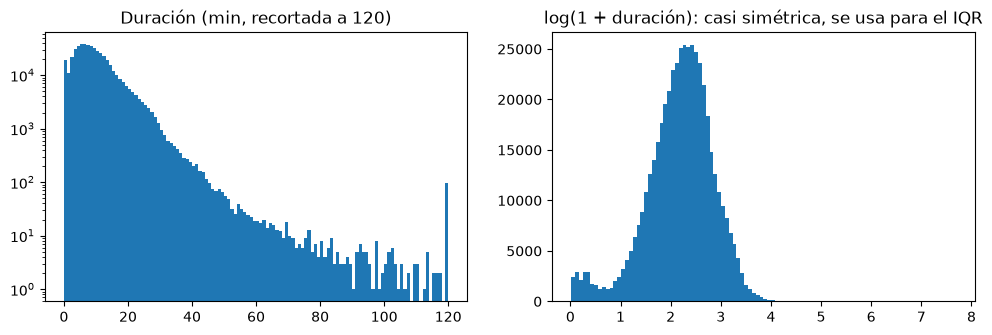

In [10]:
p = CLEANING_PARAMS
misma_estacion = datos["Origen_Id"] == datos["Destino_Id"]
print("Fin antes o igual al inicio:", (duracion <= 0).sum())
print(f"Menos de {p['min_duration_min']} min:", duracion.between(0, p["min_duration_min"], inclusive="right").sum())
print(f"Más de {p['max_duration_h']} h:", (duracion > p["max_duration_h"] * 60).sum())
print(f"Misma estación y < {p['remove_round_trip_under_min']} min:",
      (misma_estacion & (duracion < p["remove_round_trip_under_min"])).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(duracion.clip(0, 120), bins=120)
axes[0].set(title="Duración (min, recortada a 120)", yscale="log")
axes[1].hist(np.log1p(duracion[duracion > 0]), bins=100)
axes[1].set(title="log(1 + duración): casi simétrica, se usa para el IQR");

## 7. Edad y género
Justifica `clean_demographics`.

In [11]:
edad = datos["Inicio_del_viaje"].dt.year - datos["A\u00f1o_de_nacimiento"]
print(edad.describe().round(1))
print(f"Edades fuera de {p['min_age']}-{p['max_age']}:", (~edad.between(p["min_age"], p["max_age"])).sum())
datos["Genero"].value_counts(dropna=False)

count    490047.0
mean         34.7
std          13.3
min          16.0
25%          26.0
50%          32.0
75%          41.0
max        1827.0
dtype: Float64
Edades fuera de 16-90: 8


Genero
M       352032
F       134729
<NA>      3295
Name: count, dtype: int64[pyarrow]

## 8. Estaciones fuera del catálogo
Justifica `filter_unknown_stations`.

In [12]:
estaciones = load_stations()
if estaciones is not None:
    validas = set(estaciones["station_id"])
    print("Estaciones en el catálogo:", len(validas))
    print("Viajes con origen fuera del catálogo:", (~datos["Origen_Id"].isin(validas)).sum())
    print("Viajes con destino fuera del catálogo:", (~datos["Destino_Id"].isin(validas)).sum())

2026-10-25 03:15:42.917 | INFO     | mibici_demand.dataset:leer_datos:65 - Leyendo nomenclatura_2026_09.csv
2026-10-25 03:15:42.922 | INFO     | mibici_demand.dataset:load_stations:218 - Catálogo de estaciones: nomenclatura_2026_09.csv (484 estaciones)
Estaciones en el catálogo: 484
Viajes con origen fuera del catálogo: 0
Viajes con destino fuera del catálogo: 0


## Hallazgos → reglas de limpieza

**Panorama general (142 archivos, dic-2014 a sep-2026, 39,078,984 viajes):**
- Codificación: 99 archivos en UTF-8 y 43 en Windows-1252 (cp1252). `leer_datos` detecta cuál usar.
- Encabezados: las 8 columnas son las mismas en todos los meses; en 2 archivos el nombre
  `Año_de_nacimiento` viene con la codificación rota (`A}äe_nacimiento`). `estandarizar_datos` lo corrige.
- Nulos: solo en `Genero` (144,508; 0.37 %) y en el año de nacimiento (81,651; ≈0.2 %).
  Fechas, estaciones y IDs no tienen nulos.
- IDs inválidos (ID 0): no aparece ninguno en esta descarga. La regla se conserva como protección.

**Mes de ejemplo (sep-2026, 490,056 viajes):**

| Problema encontrado | Casos | Paso de `TripCleaner` | Parámetro (`config.py`) |
|---|---|---|---|
| Dos codificaciones y nombre de columna roto | 43 archivos / 2 archivos | `standardize` (`estandarizar_datos`) | — |
| Fechas en dos formatos | — | `standardize` (`estandarizar_datos`) | — |
| ID de estación o viaje = 0 | 0 | `mark_invalid_ids` | `INVALID_ID_VALUES` |
| Nulos en fechas o estaciones | 0 | `drop_missing` | — |
| Filas duplicadas (mismo `Viaje_Id`) | 758 | `drop_duplicates` | — |
| Fin antes o igual al inicio | 171 | `drop_invalid_durations` | `min_duration_min` |
| Menos de 1 minuto | 19,045 | `drop_invalid_durations` | `min_duration_min` |
| Más de 24 horas | 1 (máx. 2,167 min) | `drop_invalid_durations` | `max_duration_h` |
| Misma estación en menos de 2 min | 20,785 | `drop_false_round_trips` | `remove_round_trip_under_min` |
| Duraciones atípicas (cola larga: p99.9 = 58 min) | — | `remove_duration_outliers` | `iqr_k` |
| Edades fuera de 16-90 (máx. 1,827 años) | 8 | `clean_demographics` (se anulan) | `min_age`, `max_age` |
| Género sin dato | 3,295 | `clean_demographics` (→ `ND`) | — |
| Estaciones fuera del catálogo (484 estaciones) | 0 | `filter_unknown_stations` | — |

La duración tiene mediana de 8.4 min y una cola larga a la derecha; en escala logarítmica
es casi simétrica, por eso el IQR para outliers se calcula sobre log(duración).
La limpieza se ejecuta en el notebook `2.0` o con `make data`.